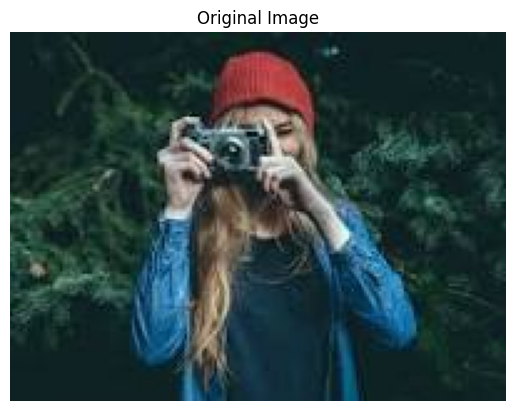

Width: 199
Height: 148
Channels: 3


In [ ]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("cvlab3img.jfif")

if image is None:
    raise FileNotFoundError("Image could not be loaded.")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()
height, width, channels = image.shape
print("Width:", width)
print("Height:", height)
print("Channels:", channels)

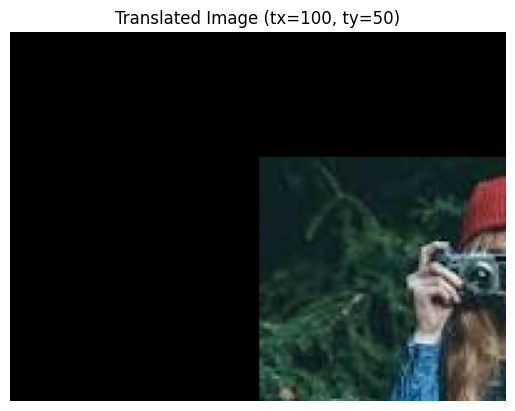

Observation for tx=100, ty=50: Notice the image shifting right and down. Parts of the image may be cropped on the left and top.


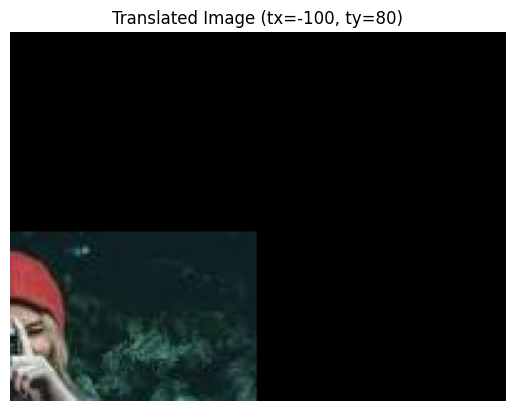

Observation for tx=-100, ty=80: Notice the image shifting left and down. Parts of the image may be cropped on the right and top.


In [ ]:
import numpy as np

# Scenario 1: tx = 100, ty = 50
tx = 100
ty = 50

M = np.float32([
    [1, 0, tx],
    [0, 1, ty]
])

translated_1 = cv2.warpAffine(
    image, M, (image.shape[1], image.shape[0])
)

plt.imshow(cv2.cvtColor(translated_1, cv2.COLOR_BGR2RGB))
plt.title(f"Translated Image (tx={tx}, ty={ty})")
plt.axis("off")
plt.show()
print(f"Observation for tx={tx}, ty={ty}: Notice the image shifting right and down. Parts of the image may be cropped on the left and top.")

# Scenario 2: Change to tx = -100, ty = 80
tx = -100
ty = 80

M = np.float32([
    [1, 0, tx],
    [0, 1, ty]
])

translated_2 = cv2.warpAffine(
    image, M, (image.shape[1], image.shape[0])
)

plt.imshow(cv2.cvtColor(translated_2, cv2.COLOR_BGR2RGB))
plt.title(f"Translated Image (tx={tx}, ty={ty})")
plt.axis("off")
plt.show()
print(f"Observation for tx={tx}, ty={ty}: Notice the image shifting left and down. Parts of the image may be cropped on the right and top.")


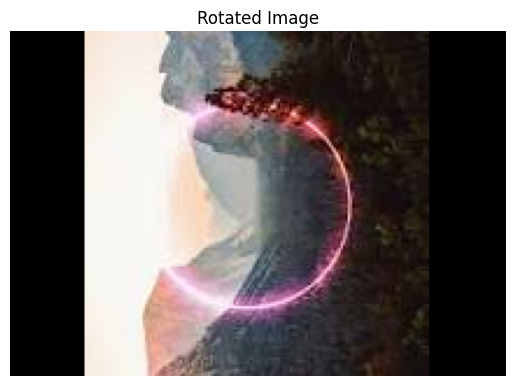

In [ ]:
height, width = image.shape[:2]
center = (width // 2, height // 2)

angle = 90
scale = 1.0
M = cv2.getRotationMatrix2D(center, angle, scale)

rotated = cv2.warpAffine(image, M, (width, height))

plt.imshow(cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB))
plt.title("Rotated Image")
plt.axis("off")
plt.show()

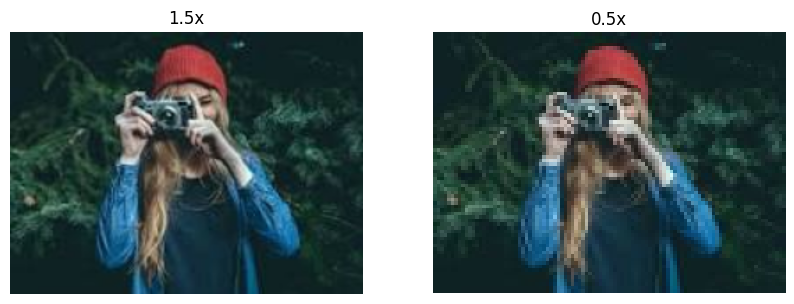

In [ ]:
scaled_up = cv2.resize(image, None, fx=1.5, fy=1.5)
scaled_down = cv2.resize(image, None, fx=0.5, fy=0.5)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(scaled_up, cv2.COLOR_BGR2RGB))
plt.title("1.5x")
plt.axis("off")
plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(scaled_down, cv2.COLOR_BGR2RGB))
plt.title("0.5x")
plt.axis("off")
plt.show()

Affine Transformation Matrix:
[[ 0.93333333 -0.13333333 40.        ]
 [-0.06666667  1.         23.33333333]]


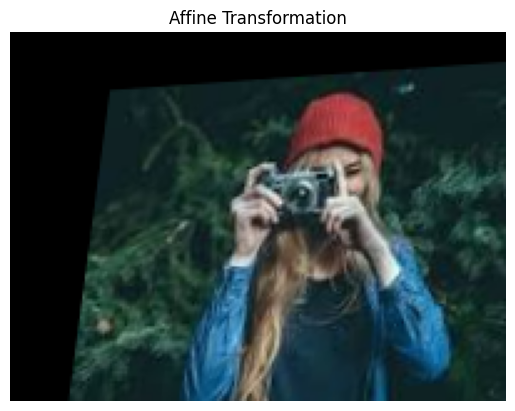

In [ ]:
pts1 = np.float32([
    [50, 50],
    [200, 50],
    [50, 200]
])

pts2 = np.float32([
    [80, 70],
    [220, 60],
    [60, 220]
])

M = cv2.getAffineTransform(pts1, pts2)
print("Affine Transformation Matrix:")
print(M)

affine = cv2.warpAffine(image, M, (width, height))

plt.imshow(cv2.cvtColor(affine, cv2.COLOR_BGR2RGB))
plt.title("Affine Transformation")
plt.axis("off")
plt.show()

Homography Matrix:
[[ 1.04471694e+00  6.52948090e-02 -1.11001175e+02]
 [ 8.92464095e-02  1.78492819e+00 -1.87417460e+02]
 [ 3.09783426e-05  3.24537898e-04  1.00000000e+00]]


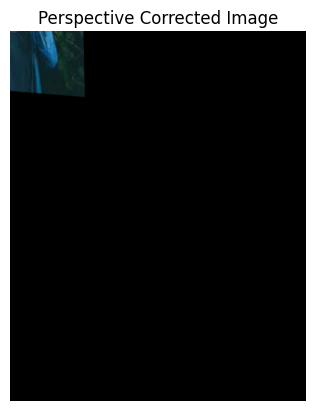

In [ ]:
src = np.float32([
    [100, 100],
    [500, 80],
    [520, 400],
    [80, 420]
])

dst = np.float32([
    [0, 0],
    [400, 0],
    [400, 500],
    [0, 500]
])

H = cv2.getPerspectiveTransform(src, dst)
print("Homography Matrix:")
print(H)

corrected = cv2.warpPerspective(image, H, (400, 500))

plt.imshow(cv2.cvtColor(corrected, cv2.COLOR_BGR2RGB))
plt.title("Perspective Corrected Image")
plt.axis("off")
plt.show()

Estimated Homography Matrix (H):
[[ 1.04471694e+00  6.52948090e-02 -1.11001175e+02]
 [ 8.92464095e-02  1.78492819e+00 -1.87417460e+02]
 [ 3.09783426e-05  3.24537898e-04  1.00000000e+00]]


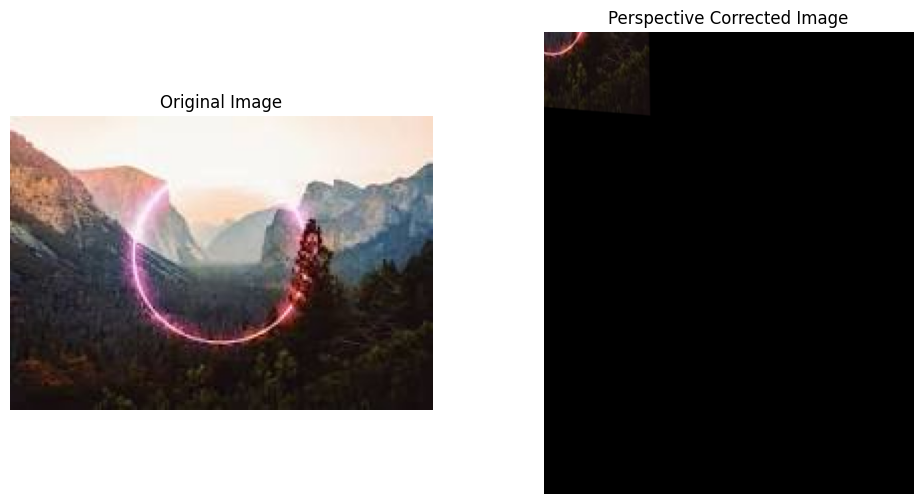

Perspective corrected image saved as 'perspective_corrected.jpg'


In [ ]:
.
image = cv2.imread('cvlab3imag2.jfif')
if image is None:
    raise FileNotFoundError("Image could not be loaded. Please check the path and filename.")

src_points = np.float32([
    [100, 100],
    [500, 80],
    [520, 400],
    [80, 420]
])

output_width = 400
output_height = 500
dst_points = np.float32([
    [0, 0],
    [output_width, 0],
    [output_width, output_height],
    [0, output_height]
])

H = cv2.getPerspectiveTransform(src_points, dst_points)
print("Estimated Homography Matrix (H):")
print(H)

corrected = cv2.warpPerspective(
    image, H, (output_width, output_height)
)
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(corrected, cv2.COLOR_BGR2RGB))
plt.title("Perspective Corrected Image")
plt.axis("off")
plt.show()
cv2.imwrite("perspective_corrected.jpg", corrected)
print("Perspective corrected image saved as 'perspective_corrected.jpg'")
